# 1 · Noiseless design: loss exponent ς and circuit depth

**Question.** For n+n qubits (n = 2, 3, 4), which loss exponent ς and how many ansatz layers p should a hardware run use, before noise enters?

**Setup** (all in `tfd_study/model.py`):
- System A: transverse-field Ising chain, H_A = Σ Z_iZ_j + Σ X_i (open chain, g = 1). B is a copy.
- Ansatz: Bell pairs |Φ⁺⟩^⊗n, then p layers of `Rx(γ₁)` on every qubit → `RZZ(γ₂)` on the chain bonds of A and B → `RXX(α₁)` and `RZZ(α₂)` on the rungs A_i–B_i. That is 4p angles for any n. For n = 2, p = 1 it is exactly the circuit in `gibbs_tfd_reproduction/tfd_circuit.py`.
- Loss: the engineered loss of Sagastizabal et al., generalised term by term to n qubits and rescaled (same minimiser):
  L(β) = [β^ς (⟨X_A+X_B⟩ + ς⟨ZZ_A+ZZ_B⟩) − ⟨H_AB⟩] / (1 + β^ς). It needs only 2 measurement settings (all-Z, all-X) for any n.
- Fidelity: qiskit's `state_fidelity` of ρ_A to the exact Gibbs state, F = (Tr√…)², as everywhere in this repo. The paper and the tfd_qi note quote √F, so their infidelities are about half of ours.

**Procedure** (`python -m tfd_study.run_noiseless_scan`): for each (n, p) and loss, minimise with exact statevector expectation values at 9 log-spaced β ∈ [0.01, 100], warm-starting each β from the previous one plus 3 random restarts (L-BFGS-B). The *exact free energy* βF[ρ_A] is optimised the same way. It is the reference: the best this circuit can be steered to.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "tfd_study").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
from tfd_study import model, devices
from tfd_study.plotting import *
apply_style()
RES = ROOT / "tfd_study" / "results"
FIGS = ROOT / "tfd_study" / "figures"; FIGS.mkdir(exist_ok=True)
pd.set_option("display.precision", 4)

## The circuit on Tuna-17

Each layer needs a 2 × n *ladder*: chain couplers inside A and inside B, plus a rung A_i–B_i. Tuna-17 contains such a ladder for every size, so no SWAPs are needed. The CZ count matches n + p(6n − 4).

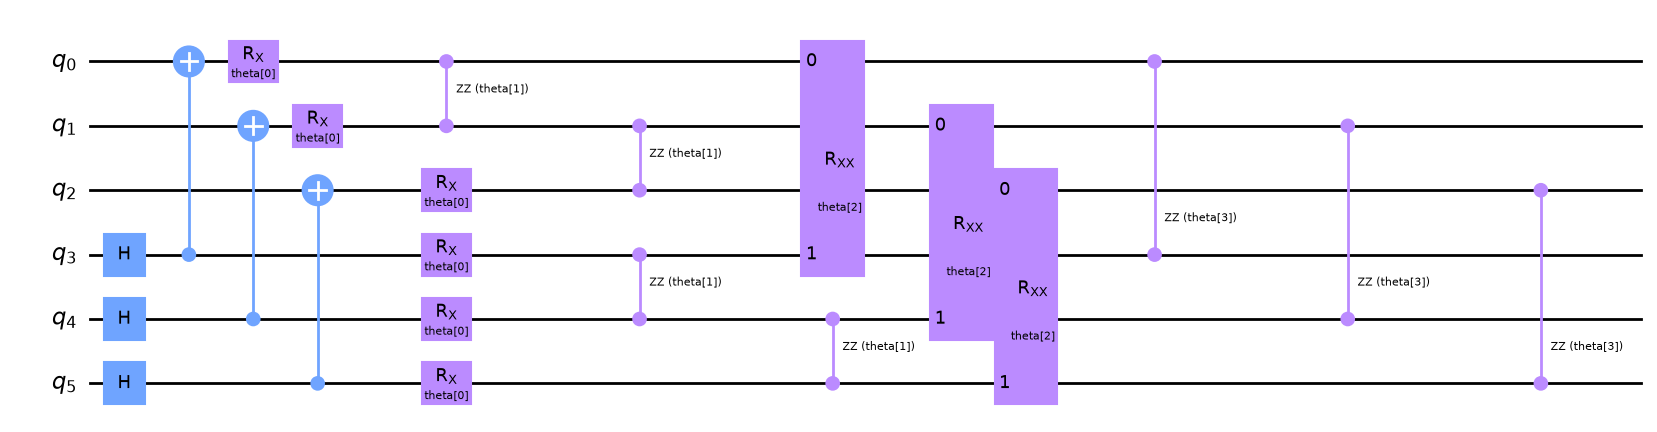

In [2]:
model.ansatz(3, 1).draw("mpl", fold=-1, style="clifford")

In [3]:
rows = []
for n in (2, 3, 4):
    lay = devices.default_layout(n)
    for p in (1, 2, 3):
        qc = devices.to_device(model.measured(n, p, np.full(4 * p, 0.3), "Z"), lay)
        ops = qc.count_ops()
        rows.append({"n": n, "p": p, "qubits": 2 * n, "angles": 4 * p, "CZ": ops.get("cz", 0),
                     "rx/ry": ops.get("rx", 0) + ops.get("ry", 0), "depth": qc.depth(),
                     "ladder placements": len(devices.ladder_layouts(n)), "layout used": lay})
hw = pd.DataFrame(rows).set_index(["n", "p"])
hw

qubits  angles  CZ  rx/ry  depth  ladder placements  \
n p                                                        
2 1       4       4  10     22     16                  8   
  2       4       8  18     34     26                  8   
  3       4      12  26     46     36                  8   
3 1       6       4  17     38     21                  8   
  2       6       8  31     61     36                  8   
  3       6      12  45     84     51                  8   
4 1       8       4  24     54     26                  4   
  2       8       8  44     88     41                  4   
  3       8      12  64    122     56                  4   

                   layout used  
n p                             
2 1               [2, 4, 5, 8]  
  2               [2, 4, 5, 8]  
  3               [2, 4, 5, 8]  
3 1        [2, 4, 7, 5, 8, 11]  
  2        [2, 4, 7, 5, 8, 11]  
  3        [2, 4, 7, 5, 8, 11]  
4 1  [0, 2, 5, 9, 1, 4, 8, 12]  
  2  [0, 2, 5, 9, 1, 4, 8, 12]  
  3  [0, 2, 5, 9, 1, 4, 8, 12]

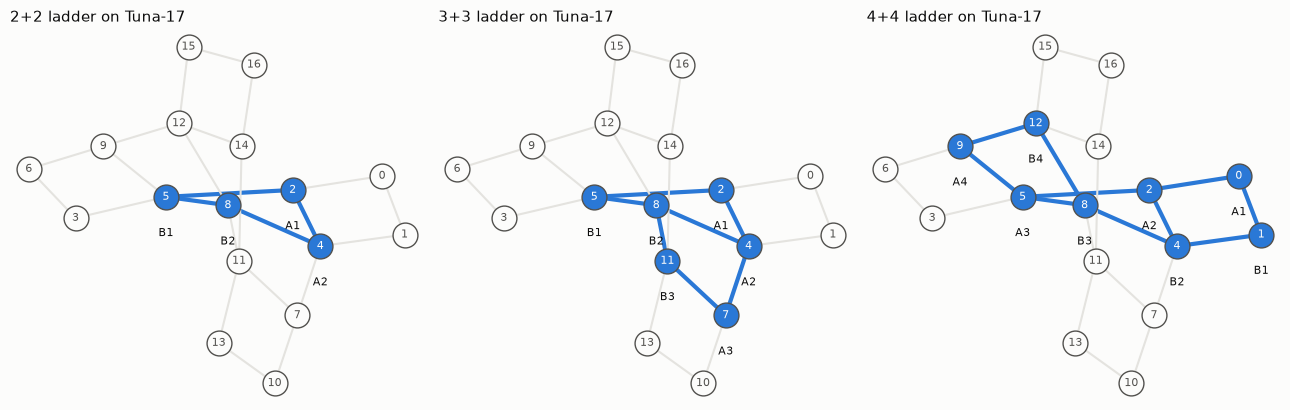

In [4]:
import rustworkx as rx
g = devices._device_graph()
pos = rx.spring_layout(g, seed=7, num_iter=300)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, n in zip(axes, (2, 3, 4)):
    lay = devices.default_layout(n)
    used = {frozenset((lay[a], lay[b])) for a, b in devices.ladder_edges(n)}
    for a, b in devices.tuna17()["edges"]:
        on = frozenset((a, b)) in used
        ax.plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]], color=SLOTS[0] if on else GRID,
                lw=3 if on else 1.5, zorder=1)
    for q in range(17):
        role = (f"A{lay.index(q) + 1}" if lay.index(q) < n else f"B{lay.index(q) - n + 1}") if q in lay else ""
        ax.scatter(*pos[q], s=320, color=SLOTS[0] if q in lay else SURFACE, edgecolor=INK_DIM, zorder=2, lw=1)
        ax.text(*pos[q], str(q), ha="center", va="center", fontsize=8, color=SURFACE if q in lay else INK_DIM, zorder=3)
        if role:
            ax.text(pos[q][0], pos[q][1] - 0.17, role, ha="center", va="top", fontsize=8, color=INK)
    ax.set_title(f"{n}+{n} ladder on Tuna-17"); ax.axis("off")
fig.tight_layout(); fig.savefig(FIGS / "tuna17_ladders.png", dpi=130, bbox_inches="tight"); plt.show()

## Which ς? Mean infidelity over β ∈ [0.01, 100]

Solid lines: the engineered loss as a function of ς, one colour per depth. Dashed: the exact free energy at the same depth (the floor). The grey vertical line is the paper's ς = 1.57. ς = 1.0 is the un-weighted proxy C₀.

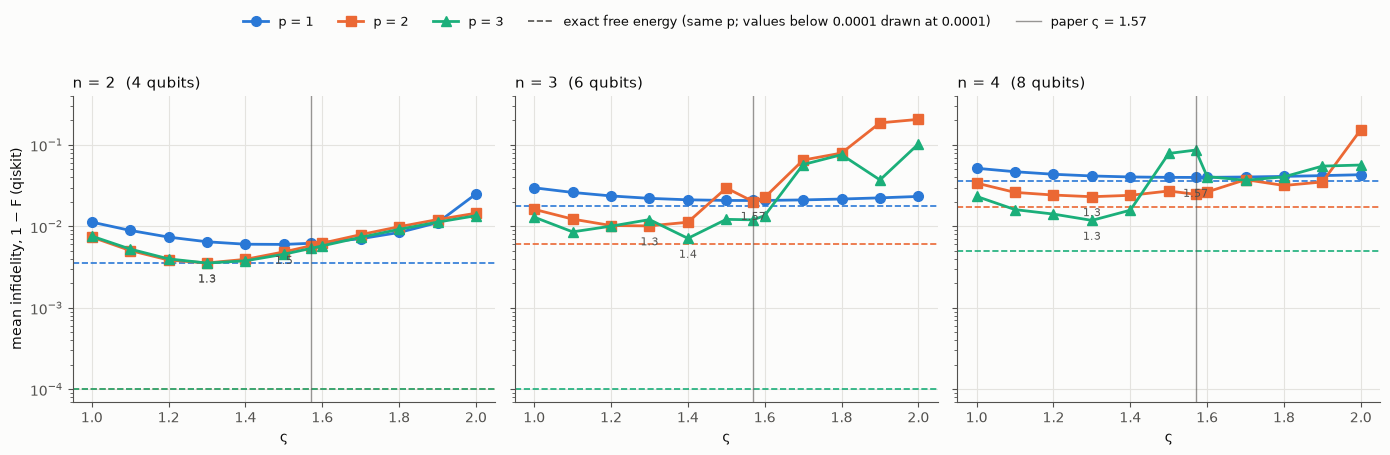

In [5]:
scan = json.loads((RES / "noiseless_scan.json").read_text())
recs = []
for r in scan["results"]:
    for row in r["rows"]:
        recs.append({"n": r["n"], "p": r["p"], "loss": "exact F" if r["loss"] == "F" else "C", "s": r["s"],
                     "beta": row["beta"], "fid": row["fid"]})
df = pd.DataFrame(recs)
FLOOR = 1e-4
summ = (df.groupby(["n", "p", "loss", "s"], dropna=False)["fid"]
          .agg(mean_infid=lambda f: float(np.mean(1 - f)), worst_F="min").reset_index())

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, n in zip(axes, (2, 3, 4)):
    for p in (1, 2, 3):
        c = summ[(summ.n == n) & (summ.p == p) & (summ.loss == "C")].sort_values("s")
        ax.plot(c.s, c.mean_infid, color=LAYER_COLORS[p], marker=LAYER_MARKERS[p], label=f"p = {p}")
        best = c.loc[c.mean_infid.idxmin()]
        ax.annotate(f"{best.s:g}", (best.s, best.mean_infid), textcoords="offset points", xytext=(0, -14),
                    ha="center", fontsize=8, color=INK_DIM)
        f = summ[(summ.n == n) & (summ.p == p) & (summ.loss == "exact F")].mean_infid.iloc[0]
        ax.axhline(max(f, FLOOR), color=LAYER_COLORS[p], ls="--", lw=1.2)
    ax.axvline(1.57, color=INK_DIM, lw=1, alpha=0.6)
    ax.set_yscale("log"); ax.set_ylim(FLOOR * 0.7, 0.4); ax.set_xlabel("ς"); ax.set_title(f"n = {n}  ({2 * n} qubits)")
axes[0].set_ylabel("mean infidelity, 1 − F (qiskit)")
fig.legend(handles=[Line2D([], [], color=LAYER_COLORS[p], marker=LAYER_MARKERS[p], label=f"p = {p}") for p in (1, 2, 3)]
           + [Line2D([], [], color=INK_DIM, ls="--", lw=1.2, label=f"exact free energy (same p; values below {FLOOR:g} drawn at {FLOOR:g})"),
              Line2D([], [], color=INK_DIM, lw=1, alpha=0.6, label="paper ς = 1.57")],
           loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(FIGS / "varsigma_scan.png", dpi=130, bbox_inches="tight"); plt.show()

In [6]:
best = (summ[summ.loss == "C"].sort_values("mean_infid").groupby(["n", "p"]).head(1)
        .set_index(["n", "p"])[["s", "mean_infid", "worst_F"]].rename(columns={"s": "best ς"}))
def pick(loss, s=None):
    m = summ[(summ.loss == loss) & ((summ.s == s) if s is not None else True)]
    return m.set_index(["n", "p"])[["mean_infid", "worst_F"]]
table = pd.concat({"best ς": best, "ς = 1.57": pick("C", 1.57), "C₀ (ς = 1)": pick("C", 1.0),
                   "exact free energy": pick("exact F")}, axis=1).sort_index()
table["CZ"] = hw["CZ"]
shown = table.copy()
for c in shown.columns:
    if c[1] == "mean_infid":
        shown[c] = shown[c].map(lambda v: f"{v:.4f}" if v >= 1e-4 else "< 0.0001")
    elif c[1] == "worst_F":
        shown[c] = shown[c].map(lambda v: f"{v:.3f}")
shown

best ς                      ς = 1.57         C₀ (ς = 1)          \
    best ς mean_infid worst_F mean_infid worst_F mean_infid worst_F   
n p                                                                   
2 1   1.50     0.0060   0.989     0.0062   0.988     0.0113   0.968   
  2   1.30     0.0036   0.986     0.0058   0.986     0.0074   0.972   
  3   1.30     0.0036   0.984     0.0054   0.990     0.0076   0.971   
3 1   1.57     0.0208   0.955     0.0208   0.955     0.0298   0.933   
  2   1.30     0.0102   0.972     0.0202   0.903     0.0162   0.961   
  3   1.40     0.0071   0.984     0.0120   0.970     0.0130   0.962   
4 1   1.57     0.0400   0.906     0.0400   0.906     0.0518   0.899   
  2   1.30     0.0232   0.937     0.0248   0.907     0.0340   0.931   
  3   1.30     0.0119   0.969     0.0866   0.536     0.0234   0.949   

    exact free energy          CZ  
           mean_infid worst_F      
n p                                
2 1            0.0036   0.991  10  
  2          < 0.0001   1.000  18  
  3          < 0.0001   1.000  26  
3 1            0.0176   0.956  17  
  2            0.0060   0.981  31  
  3          < 0.0001   0.999  45  
4 1            0.0363   0.907  24  
  2            0.0173   0.944  44  
  3            0.0050   0.976  64

## Where the paper's ς = 1.57 fails: infidelity versus β

At depth p = 2 and 3 the fixed ς = 1.57 leaves isolated failures at low temperature. The re-fitted ς follows the exact free energy much more closely.

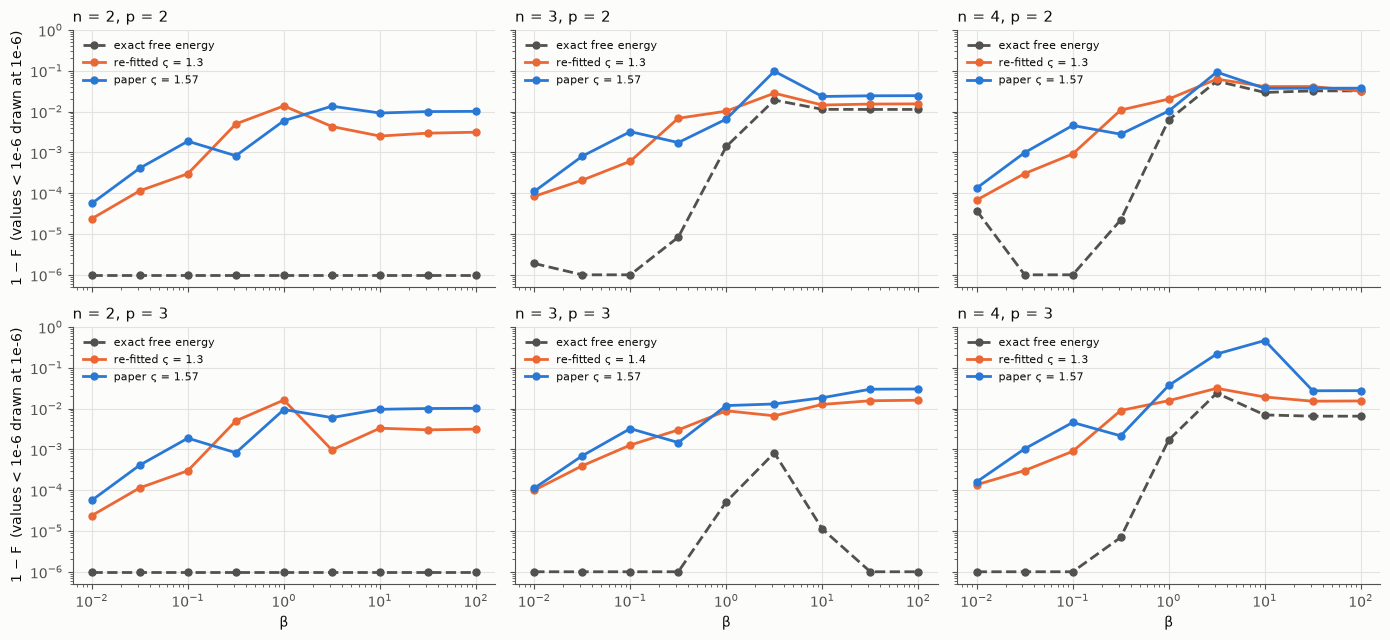

In [7]:
def curve(n, p, loss, s=None):
    m = df[(df.n == n) & (df.p == p) & (df.loss == loss)]
    if s is not None:
        m = m[m.s == s]
    return m.sort_values("beta")

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharex=True, sharey=True)
for i, p in enumerate((2, 3)):
    for j, n in enumerate((2, 3, 4)):
        ax = axes[i, j]
        s_best = best.loc[(n, p), "best ς"]
        for (lbl, loss, s, col, ls) in (("exact free energy", "exact F", None, INK_DIM, "--"),
                                        (f"re-fitted ς = {s_best:g}", "C", s_best, SLOTS[1], "-"),
                                        ("paper ς = 1.57", "C", 1.57, SLOTS[0], "-")):
            c = curve(n, p, loss, s)
            ax.plot(c.beta, np.maximum(1 - c.fid, 1e-6), color=col, ls=ls, marker="o", ms=5, label=lbl)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(5e-7, 1); ax.set_title(f"n = {n}, p = {p}")
        ax.legend(fontsize=8, loc="upper left")
for ax in axes[-1]: ax.set_xlabel("β")
for ax in axes[:, 0]: ax.set_ylabel("1 − F  (values < 1e-6 drawn at 1e-6)")
fig.tight_layout(); fig.savefig(FIGS / "infidelity_vs_beta.png", dpi=130, bbox_inches="tight"); plt.show()

## How deep must the circuit be?

Worst-case fidelity over β with the exact free energy, i.e. the most the circuit can do. Each extra layer adds 6n − 4 CZ gates, so this gain must be weighed against noise (notebook 3).

In [8]:
ceil = summ[summ.loss == "exact F"].pivot(index="n", columns="p", values="worst_F")
ceil.columns = [f"p = {p}" for p in ceil.columns]
ceil_cz = hw["CZ"].unstack()
ceil_cz.columns = [f"CZ, p = {p}" for p in ceil_cz.columns]
pd.concat([ceil.round(3), ceil_cz], axis=1)

,p = 1,p = 2,p = 3,"CZ, p = 1","CZ, p = 2","CZ, p = 3"
n,,,,,,
2,0.991,1.000,1.000,10,18,26
3,0.956,0.981,0.999,17,31,45
4,0.907,0.944,0.976,24,44,64


## Conclusions (noiseless)

1. **One layer: keep ς ≈ 1.5.** The loss is flat between 1.4 and 1.6, and the paper's 1.57 is within 3 % of the best for every n.
2. **Two or more layers: ς must come down to about 1.3.**
   - The paper's 1.57 then leaves isolated low-temperature failures. The worst-case fidelity is 0.903 for 3+3 with 2 layers and **0.536 for 4+4 with 3 layers** (vs 0.972 and 0.969 at ς = 1.3).
   - Above ς ≈ 1.5 the deeper circuits break down.
   - Around the optimum the curve is narrow and not smooth (3+3 with 3 layers: 1.4 best, 1.3 and 1.5 clearly worse). The fit is single-seed and scored on its own β grid, so these values are approximate.
3. **Depth is what limits low temperature, not the loss.** With the exact free energy, the worst-case fidelity rises from p = 1 to 3: 0.956 → 0.981 → 0.999 for 3+3 and 0.907 → 0.944 → 0.976 for 4+4. 2+2 is exact from p = 2. The engineered loss loses up to about 0.01–0.02 more on top of that.
4. **Each layer costs 6n − 4 CZ.** 4+4 with 3 layers is 64 CZ. Whether the extra depth survives Tuna-17's noise is the question for notebooks 2 and 3.
5. **Tuna-17 fits a ladder for every size** (8, 8 and 4 placements, no SWAPs). The 2+2 layout is the one already used on hardware (qubits 2-4-5-8).

ς used from here on (`best_varsigma()`): 1.5 / 1.3 / 1.3 for 2+2, 1.57 / 1.3 / 1.4 for 3+3, and 1.57 / 1.3 / 1.3 for 4+4 at p = 1 / 2 / 3.